# Лабораторная работа №4. Использование библиотеки pandas
## Задание 1. Олимпийские игры
Все подпункты задания выполнены последовательно. Файл `athlete_events.csv` должен находиться рядом с блокнотом.
Необходимы Python, pandas и matplotlib. Результаты выполнения сохранены в блокноте.

## 1. Загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

df = pd.read_csv('athlete_events.csv')
print(f'Строк: {len(df):,}; столбцов: {df.shape[1]}')
display(df.head())

Строк: 271,116; столбцов: 15


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


## 2. Число заполненных значений и пропуски

In [2]:
completeness = pd.DataFrame({'Заполнено': df.count(), 'Пропущено': df.isna().sum()})
display(completeness)
print('Пропуски есть в:', ', '.join(completeness.index[completeness['Пропущено'] > 0]))
print('Больше всего пропусков:', completeness['Пропущено'].idxmax())

,Заполнено,Пропущено
ID,271116,0
Name,271116,0
Sex,271116,0
Age,261642,9474
Height,210945,60171
Weight,208241,62875
Team,271116,0
NOC,271116,0
Games,271116,0
Year,271116,0


Пропуски есть в: Age, Height, Weight, Medal
Больше всего пропусков: Medal


В `Medal` значение NA означает отсутствие медали, а не неизвестный результат. Пропуски возраста, роста и веса означают отсутствие соответствующих сведений. Средние считаются по известным значениям, без заполнения пропусков нулями.

## 3. Описательная статистика возраста, роста и веса

In [3]:
display(df[['Age', 'Height', 'Weight']].describe().round(2))

,Age,Height,Weight
count,261642.00,210945.00,208241.00
mean,25.56,175.34,70.70
std,6.39,10.52,14.35
min,10.00,127.00,25.00
25%,21.00,168.00,60.00
50%,24.00,175.00,70.00
75%,28.00,183.00,79.00
max,97.00,226.00,214.00


## 4.1. Самый молодой участник Олимпиады 1992 года

In [4]:
games_1992 = df.loc[df['Year'].eq(1992)]
min_age = games_1992['Age'].min()
youngest = games_1992.loc[games_1992['Age'].eq(min_age), ['Name', 'Age', 'Season', 'Sport', 'Event']].drop_duplicates()
print(f'Минимальный известный возраст: {min_age:g} лет.')
display(youngest)

Минимальный известный возраст: 11 лет.


,Name,Age,Season,Sport,Event
73461,Carlos Bienvenido Front Barrera,11.0,Summer,Rowing,Rowing Men's Coxed Eights


## 4.2. Все виды спорта без повторений

In [5]:
sports = df['Sport'].dropna().drop_duplicates().sort_values().reset_index(drop=True)
print(f'Всего видов спорта: {len(sports)}')
with pd.option_context('display.max_rows', None):
    display(sports.to_frame('Вид спорта'))

Всего видов спорта: 66


,Вид спорта
0,Aeronautics
1,Alpine Skiing
2,Alpinism
3,Archery
4,Art Competitions
5,Athletics
6,Badminton
7,Baseball
8,Basketball
9,Basque Pelota


## 4.3. Средний рост теннисисток на Играх 2000 года
Для среднего по спортсменкам оставляем одну запись на ID: участие в одиночном и парном разрядах не должно удваивать вес спортсменки.

In [6]:
tennis = df.loc[df['Year'].eq(2000) & df['Sex'].eq('F') & df['Sport'].eq('Tennis')]
tennis_players = tennis.drop_duplicates('ID')
print(f"Средний рост по уникальным спортсменкам: {tennis_players['Height'].mean():.2f} см.")
print(f"Число спортсменок с известным ростом: {tennis_players['Height'].count()}.")
print(f"Для сравнения, среднее по всем записям участия: {tennis['Height'].mean():.2f} см.")

Средний рост по уникальным спортсменкам: 171.81 см.
Число спортсменок с известным ростом: 88.
Для сравнения, среднее по всем записям участия: 171.79 см.


## 4.4. Золотые медали Китая в настольном теннисе в 2008 году
Покажем и число наград спортсменов, и число побед страны. Командная победа даёт одну медаль в медальном зачёте страны, хотя награждаются несколько игроков.

In [7]:
china_gold = df.loc[df['Year'].eq(2008) & df['NOC'].eq('CHN') & df['Sport'].eq('Table Tennis') & df['Medal'].eq('Gold')]
display(china_gold[['Name', 'Event', 'Medal']])
print('Золотых медалей в зачёте Китая:', china_gold['Event'].nunique())
print('Индивидуальных записей о награждении:', len(china_gold))

,Name,Event,Medal
86741,Guo Yue,Table Tennis Women's Team,Gold
144925,Ma Lin,Table Tennis Men's Singles,Gold
144926,Ma Lin,Table Tennis Men's Team,Gold
256549,Wang Hao,Table Tennis Men's Team,Gold
256666,Wang Liqin,Table Tennis Men's Team,Gold
256711,Wang Nan,Table Tennis Women's Team,Gold
269030,Zhang Yining,Table Tennis Women's Singles,Gold
269031,Zhang Yining,Table Tennis Women's Team,Gold


Золотых медалей в зачёте Китая: 4
Индивидуальных записей о награждении: 8


## 4.5. Изменение числа видов спорта: 1988 и 2004 годы

In [8]:
sport_counts = df.loc[df['Season'].eq('Summer') & df['Year'].isin([1988, 2004])].groupby('Year')['Sport'].nunique()
display(sport_counts.to_frame('Число видов спорта'))
delta = sport_counts.loc[2004] - sport_counts.loc[1988]
print(f'Изменение: {delta:+d} видов спорта ({delta / sport_counts.loc[1988] * 100:+.2f}%).')

,Число видов спорта
Year,
1988,27
2004,34


Изменение: +7 видов спорта (+25.93%).


## 4.6. Возраст мужчин-кёрлингистов, Олимпиада 2014 года

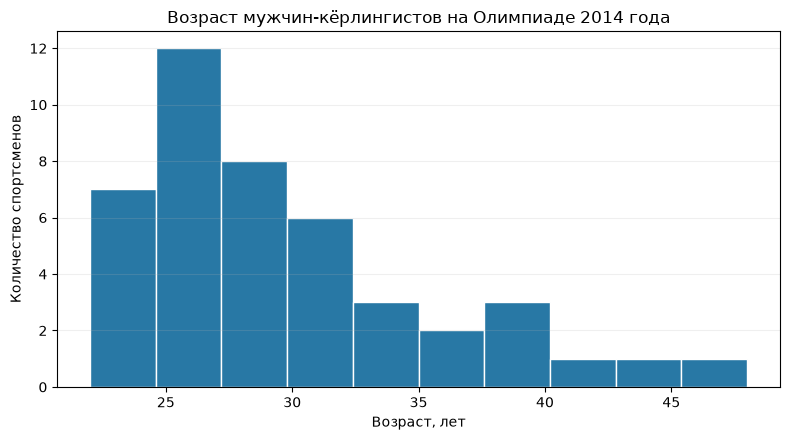

Участников: 44; возраст известен для 44.


In [9]:
curling = df.loc[df['Year'].eq(2014) & df['Sport'].eq('Curling') & df['Sex'].eq('M')].drop_duplicates('ID')
ages = curling['Age'].dropna()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(ages, bins=10, edgecolor='white', color='#2878a5')
ax.set(title='Возраст мужчин-кёрлингистов на Олимпиаде 2014 года', xlabel='Возраст, лет', ylabel='Количество спортсменов')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
plt.show()
print(f'Участников: {len(curling)}; возраст известен для {len(ages)}.')

## 4.7. Медали и средний возраст по странам, зимние Игры 2006 года
Основной расчёт `count` считает награждения спортсменов, как они представлены в исходной таблице.
Средний возраст считаем по уникальным участникам каждой страны, включая спортсменов без медалей.
Рядом приводим число медалей в зачёте стран: командные награды объединяем по стране, дисциплине и достоинству медали.

In [10]:
winter = df.loc[df['Year'].eq(2006) & df['Season'].eq('Winter')].copy()
awards = winter.groupby('NOC')['Medal'].count().rename('Награждений спортсменов')
mean_age = winter.drop_duplicates(['NOC', 'ID']).groupby('NOC')['Age'].mean().rename('Средний возраст участников')
national_medals = winter.dropna(subset=['Medal']).drop_duplicates(['NOC', 'Event', 'Medal'])
national_counts = national_medals.groupby('NOC').size().rename('Медалей в зачёте стран')
summary = pd.concat([awards, mean_age, national_counts], axis=1)
summary = summary.loc[summary['Награждений спортсменов'].gt(0)].sort_values('Награждений спортсменов', ascending=False)
summary['Медалей в зачёте стран'] = summary['Медалей в зачёте стран'].astype(int)
display(summary.round(2))

,Награждений спортсменов,Средний возраст участников,Медалей в зачёте стран
NOC,,,
CAN,69,25.81,24
SWE,64,27.00,14
GER,54,26.87,29
USA,52,25.79,25
RUS,41,25.61,22
FIN,41,26.63,9
AUT,30,27.58,23
CZE,27,26.89,4
ITA,25,26.58,11


## 4.8. Сводная таблица награждений по странам и достоинству медали

In [11]:
medal_pivot = winter.pivot_table(index='NOC', columns='Medal', values='ID', aggfunc='count', fill_value=0)
medal_pivot = medal_pivot.reindex(columns=['Gold', 'Silver', 'Bronze'], fill_value=0).astype(int)
display(medal_pivot)
print('Пропусков в сводной таблице:', medal_pivot.isna().sum().sum())
print('Дополнительно: медальный зачёт стран (командные награды считаются один раз):')
national_pivot = national_medals.pivot_table(index='NOC', columns='Medal', values='ID', aggfunc='count', fill_value=0)
display(national_pivot.reindex(columns=['Gold', 'Silver', 'Bronze'], fill_value=0).astype(int))

Medal,Gold,Silver,Bronze
NOC,,,
AUS,1,0,1
AUT,16,7,7
BLR,0,1,0
BUL,0,1,0
CAN,30,28,11
CHN,2,5,6
CRO,1,2,0
CZE,1,2,24
EST,3,0,0


Пропусков в сводной таблице: 0
Дополнительно: медальный зачёт стран (командные награды считаются один раз):


Medal,Gold,Silver,Bronze
NOC,,,
AUS,1,0,1
AUT,9,7,7
BLR,0,1,0
BUL,0,1,0
CAN,7,10,7
CHN,2,4,5
CRO,1,2,0
CZE,1,2,1
EST,3,0,0
